# 01 - APTOS 2019 exploratory data analysis

Data expected at `/content/data/aptos` (`train.csv` + `train_images/`).

In [ ]:
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path('/content/data/aptos')
FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT / 'train.csv')
df['path'] = df['id_code'].apply(lambda x: ROOT / 'train_images' / f'{x}.png')
summary = {'n_images': int(len(df))}
print(len(df), 'images')

3662 images


           count  share
diagnosis              
0           1805  0.493
1            370  0.101
2            999  0.273
3            193  0.053
4            295  0.081


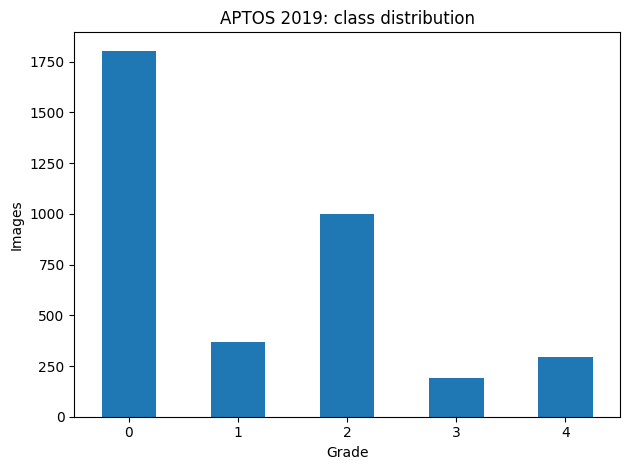

In [ ]:
counts = df['diagnosis'].value_counts().sort_index()
print(pd.DataFrame({'count': counts, 'share': (counts / len(df)).round(3)}))
ax = counts.plot(kind='bar', title='APTOS 2019: class distribution', rot=0)
ax.set_xlabel('Grade'); ax.set_ylabel('Images')
plt.tight_layout(); plt.savefig(FIG / 'class_distribution.png', dpi=150); plt.show()
summary['class_counts'] = {int(k): int(v) for k, v in counts.items()}

In [ ]:
sample = df.sample(300, random_state=0)
sizes = pd.DataFrame([Image.open(p).size for p in sample['path']], columns=['width', 'height'])
print(sizes.describe().round(0))
summary['size_sample'] = {c: {'min': int(sizes[c].min()), 'median': int(sizes[c].median()), 'max': int(sizes[c].max())} for c in sizes}

        width  height
count   300.0   300.0
mean   2040.0  1541.0
std     864.0   538.0
min     640.0   480.0
25%    1050.0  1050.0
50%    2144.0  1536.0
75%    2588.0  1958.0
max    4288.0  2848.0


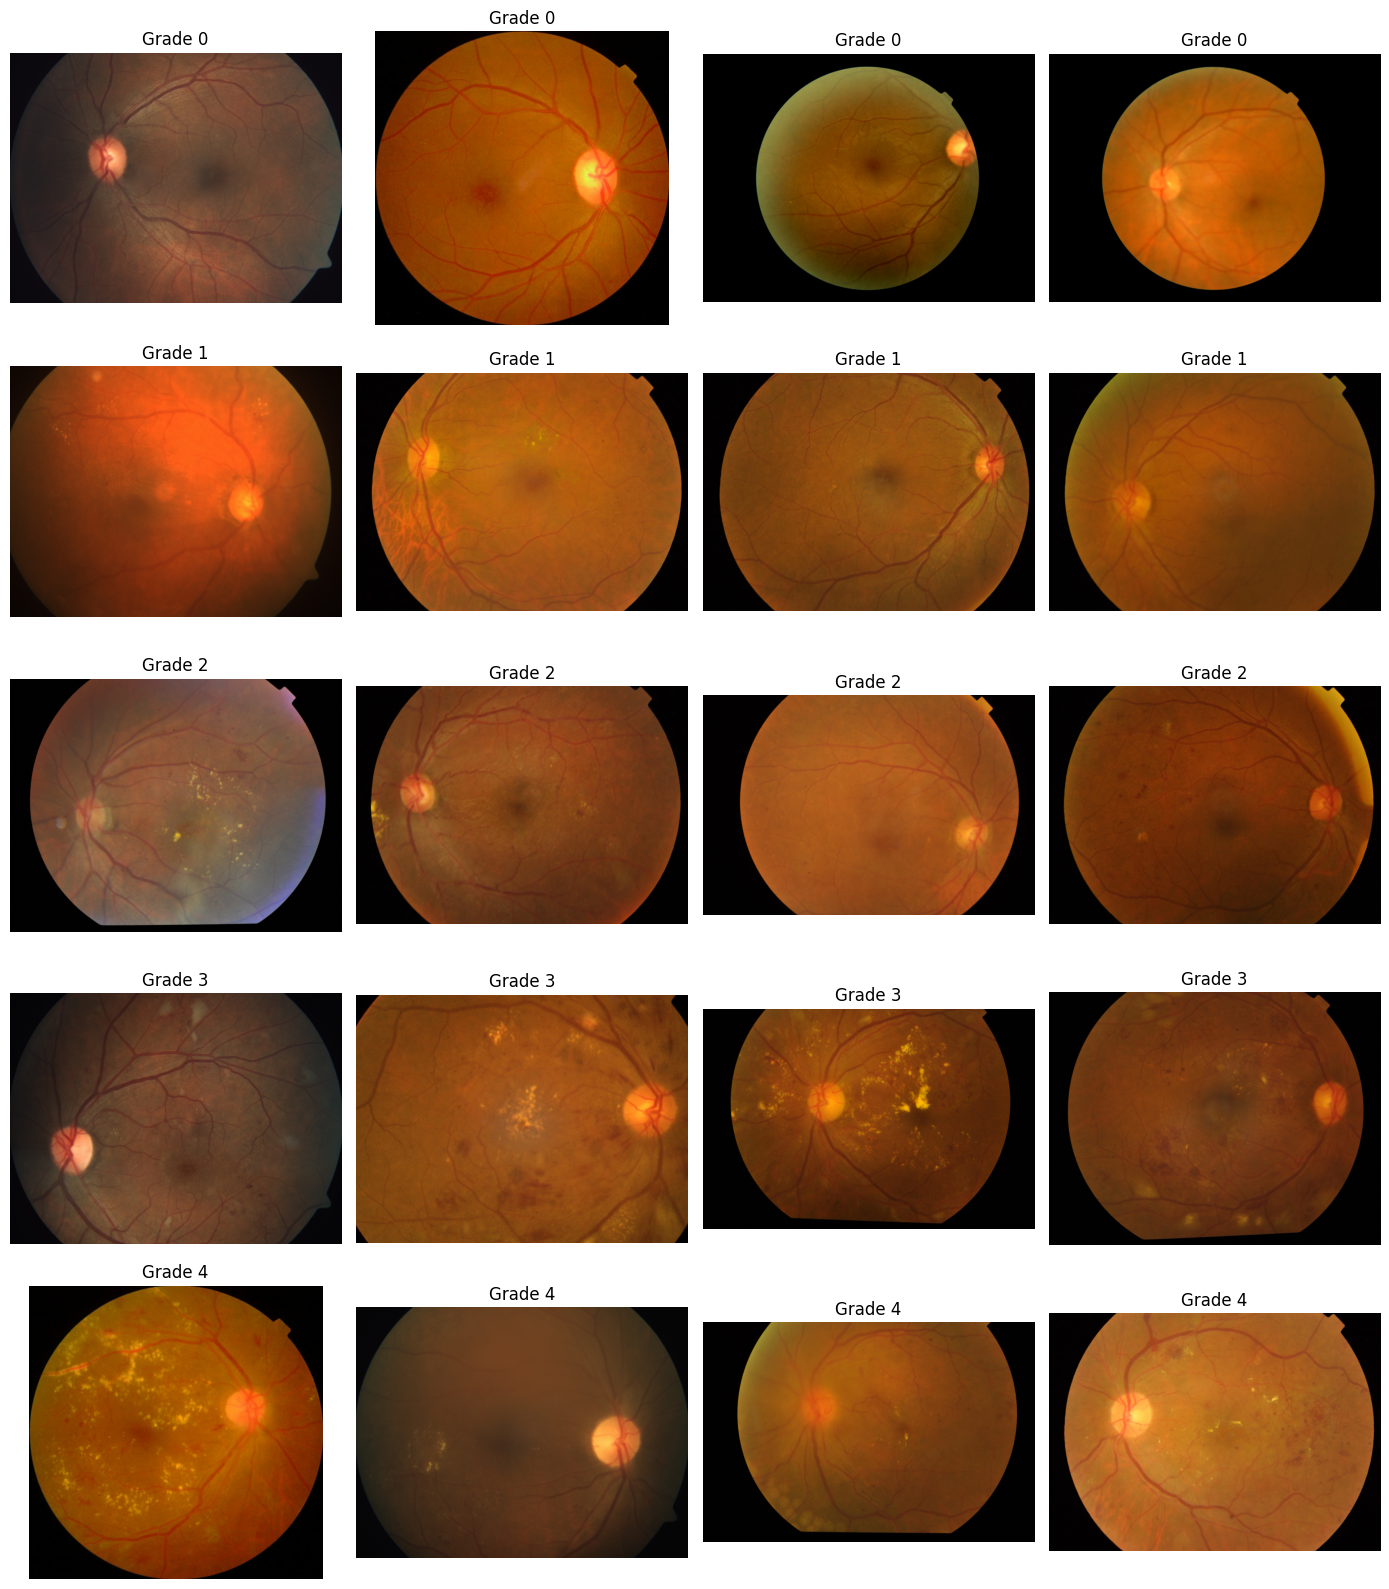

In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(14, 16))
for cls in range(5):
    pick = df[df.diagnosis == cls].sample(4, random_state=1)
    for ax, (_, row) in zip(axes[cls], pick.iterrows()):
        ax.imshow(Image.open(row.path)); ax.axis('off'); ax.set_title(f'Grade {cls}')
plt.tight_layout(); plt.savefig(FIG / 'sample_grid.png', dpi=80); plt.show()

In [ ]:
def md5(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

df['hash'] = df['path'].apply(md5)
dup = int(df['hash'].duplicated().sum())
conflict = int((df.groupby('hash')['diagnosis'].transform('nunique') > 1).sum())
print('Duplicate files (beyond first copy):', dup)
print('Images in groups with conflicting labels:', conflict)
summary['duplicates'] = dup; summary['conflicting_label_images'] = conflict

Duplicate files (beyond first copy): 128
Images in groups with conflicting labels: 62


In [ ]:
with open('../reports/eda_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "n_images": 3662,
  "class_counts": {
    "0": 1805,
    "1": 370,
    "2": 999,
    "3": 193,
    "4": 295
  },
  "size_sample": {
    "width": {
      "min": 640,
      "median": 2144,
      "max": 4288
    },
    "height": {
      "min": 480,
      "median": 1536,
      "max": 2848
    }
  },
  "duplicates": 128,
  "conflicting_label_images": 62
}


## Findings

This APTOS 2019 dataset contains the 3662 images with 5 diagnosis stages. The distribution among these stages are shown in the class distribution plot which can be interpret as follows:
| diagnosis | count | share |
|-----------|-------|-------|         
|0          | 1805  | 0.493 |
|1          |  370  | 0.101 |
|2          |  999  | 0.273 |
|3          |  193  | 0.053 |
|4          |  295  | 0.081 |   

According to these numbers, this image dataset exhibits a noticeable class imblance, where the number of images varies significantly accross different classses. Classs 0 is well represented with 1805 images, while others contain considerably fewer samples. Class 3 is the minority class containing only 193 images.

This uneven distribution may introduce bias during model training, as the model may become more inclined to predict the majority classes while failing to effectively identify minority classes.

And also, this dataset contains 128 duplicates and 62 conflicting lable images. These duplicate images may introduce redundancy and affect the reliablity of model evaluation, particularly when identical images are distributed across training, validation and testing subsets.

The dataset contains images with varying dimensions, indicating that the source images were not collected or stored using a uniform resolution.

The observed image dimension ranges are:

| Dimension   | Minimum | Median | Maximum |
|-------------|---------|--------|---------|
| Width (px)  |    640  |  2144  |  4288   |
| Height (px) |    480  |  1536  |  2848   |

 Differences in image resolution may affect the amount of visual information available for feature extraction. Images with lower resolutions may contain fewer fine-grained details, while higher-resolution images may require additional computational resources.